# Publication figures and tables — ZTF 8-year kilonova rate limits

Every figure and number in this notebook is computed from the results snapshot chosen in the settings cell
(see `knrates/collect.py`). Figures are written to `paper/figures/` (PDF + PNG) and the summary table to
`paper/table1_master_rate_limits.{csv,tex}`.

**Status of inputs** (see `docs/review_2026-11.md`):
* Suites 01 and 07 (fixed-parameter ensembles, $100\times10^6$ injections per model) — used for Figures 1–5 and Table 1.
* Suite 02 (criteria sweep) — filter corrected; Figure 6 is marked PRELIMINARY until the candidate ensemble has been
  re-simulated with the current envelope (check `02_granular_criteria_sweep_analysis.ipynb`, Section 1).
* No figure here uses hard-coded numbers; the earlier "archetype optimism bias", Pareto-frontier and imposter-purity
  figures had no simulation behind them and are not produced.

In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"     # "latest" | time stamp or prefix (e.g. "20261109") | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = True     # write PDF+PNG copies of every figure to FIG_DIR
FIG_DIR = "paper/figures"
INCLUDE_METZGER = True  # False removes the one-zone Metzger models (all suites) from every table and figure
LABELS = "paper"        # "working": model labels name the analysis suite (S01, S07, ...) for internal use
                        # "paper":   labels describe only the physics (use for publication figures)
# ---------------------------------------------------------------------------
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from knrates import load_snapshot, list_snapshots
from knrates import analysis as A, literature as L, plotting as P
from knrates.stats import LN20, rate_upper_limit, summarize_runs

P.use_style("paper")
P.set_label_mode(LABELS)
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", "{:.4g}".format)
snap = load_snapshot(SNAPSHOT)
if not INCLUDE_METZGER:
    snap = snap.exclude_models(lambda m: "Metzger" in m)
print(snap.describe())
print("\nAvailable snapshots:", [p.name for p in list_snapshots()])

def save(fig, name):
    if SAVE_FIGURES:
        for p in P.savefig(fig, name, ROOT / FIG_DIR):
            print("saved", p.relative_to(ROOT))

Snapshot: knrates_results_latest.zip (created 20261110T212021Z, git e8ca32f2)
  models_lightcurves               7,965 rows
  suite01_runs                       300 rows
  suite01_sources                 76,976 rows
  suite01_texp_month                 291 rows
  suite01_z_hist                     360 rows
  suite02_candidate_runs             303 rows
  suite02_fiducial                     3 rows
  suite02_grid_marginals             144 rows
  suite02_grid_size                    3 rows
  suite02_slices_1d                  135 rows
  suite02_slices_2d                2,625 rows
  suite03_runs                        36 rows
  suite07_runs                       400 rows
  suite07_sources                254,591 rows
  suite07_texp_month                 388 rows
  suite07_z_hist                     480 rows

Available snapshots: ['knrates_results_latest.zip']


In [2]:
runs = pd.concat([snap["suite01_runs"], snap.get("suite07_runs", pd.DataFrame())], ignore_index=True)
tm = pd.concat([snap["suite01_texp_month"], snap.get("suite07_texp_month", pd.DataFrame())], ignore_index=True)
zh = pd.concat([snap["suite01_z_hist"], snap.get("suite07_z_hist", pd.DataFrame())], ignore_index=True)
src = pd.concat([snap["suite01_sources"], snap.get("suite07_sources", pd.DataFrame())], ignore_index=True)
ALL = [m for m in P.MODEL_STYLE if m in set(runs.model)]
lim = A.headline_limits(runs, ALL)
L_ = lim.set_index("model")
display(lim[["model", "n_runs", "n_detected", "efficiency", "vt_gpc3_yr", "r90", "r95", "r95_err_mc", "r99"]])

,model,n_runs,n_detected,efficiency,vt_gpc3_yr,r90,r95,r95_err_mc,r99
0,Bu2026Fixed,100,184316,0.001843,0.0156,147.6,192,0.4394,295.2
1,Bu2026Vary,100,53948,0.0005395,0.004515,510,663.6,2.973,1020
2,Metzger,100,47831,0.0004783,0.003963,581,755.8,3.547,1162
3,GW170817_Bu2026_FixedView,100,186028,0.00186,0.01572,146.5,190.6,0.4026,293
4,GW170817_Bu2026_Isotropic,100,57435,0.0005743,0.004804,479.3,623.6,2.363,958.7
5,GW170817_Metzger_Blue,100,1316108,0.01316,0.1105,20.84,27.12,0.02331,41.69
6,GW170817_Metzger_Mean,100,468311,0.004683,0.03977,57.9,75.33,0.1024,115.8


## Figure 1 — Sensitivity accumulated over the ZTF survey

Published ZTF limits are placed at the end of the data they used; those with a model counterpart in the figure are labelled with the difference and carried forward (dashed).

Literature values available for the next figure (select them with the list at the top of the plotting cell):

- `andreoni2020_gw170817` — [Andreoni et al. 2020](https://arxiv.org/abs/2008.00008): ZTF (first 23 months), GW170817-like: R < 1775 Gpc^-3 yr^-1 (95%)
- `andreoni2020_possis_isotropic` — [Andreoni et al. 2020](https://arxiv.org/abs/2008.00008): ZTF (first 23 months), POSSIS, uniform viewing angle: R < 4029 Gpc^-3 yr^-1 (95% (implied))
- `andreoni2020_tophat_m16_2det` — [Andreoni et al. 2020](https://arxiv.org/abs/2008.00008): ZTF (first 23 months), top-hat M=-16, 2 detections: R < 930 Gpc^-3 yr^-1 (95%)
- `andreoni2020_linear_decline_2det` — [Andreoni et al. 2020](https://arxiv.org/abs/2008.00008): ZTF (first 23 months), linear decline M=-16.5, 0.7 mag/d, 2 det.: R < 937 Gpc^-3 yr^-1 (95%)
- `andreoni2021_ztfrest_combined` — [Andreoni et al. 2021](https://arxiv.org/abs/2104.06352): ZTF (ZTFReST + 2020 search), GW170817-like: R < 900 Gpc^-3 yr^-1 (not stated (95% per secondary source))

saved paper/figures/fig1_survey_volume_timeline.pdf
saved paper/figures/fig1_survey_volume_timeline.png


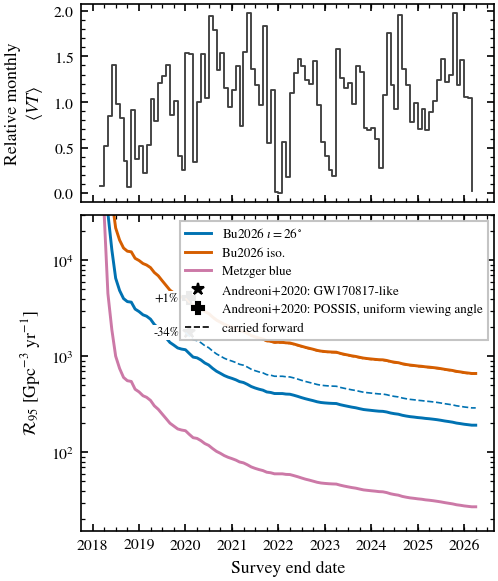

In [3]:
# Literature values to draw (remove entries to hide them). Options:
#   'andreoni2020_gw170817'                  ZTF (first 23 months), GW170817-like: R < 1775 Gpc^-3 yr^-1 (95%)
#   'andreoni2020_possis_isotropic'          ZTF (first 23 months), POSSIS, uniform viewing angle: R < 4029 Gpc^-3 yr^-1 (95% (implied))
#   'andreoni2020_tophat_m16_2det'           ZTF (first 23 months), top-hat M=-16, 2 detections: R < 930 Gpc^-3 yr^-1 (95%)
#   'andreoni2020_linear_decline_2det'       ZTF (first 23 months), linear decline M=-16.5, 0.7 mag/d, 2 det.: R < 937 Gpc^-3 yr^-1 (95%)
#   'andreoni2021_ztfrest_combined'          ZTF (ZTFReST + 2020 search), GW170817-like: R < 900 Gpc^-3 yr^-1 (not stated (95% per secondary source))
SHOW_LITERATURE = ["andreoni2020_gw170817", "andreoni2020_possis_isotropic"]

selected = L.select(SHOW_LITERATURE, "rate_limits")
MAIN = [m for m in ["Bu2026Fixed", "Bu2026Vary", "GW170817_Metzger_Blue"] if m in ALL]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(P.COL_WIDTH, 3.9), sharex=True, height_ratios=[1, 1.6])
e0 = A.vt_by_epoch(tm, runs, MAIN[0])
ax1.step(e0["month"].dt.to_timestamp(), e0["vt_month"] / e0["vt_month"].mean(), where="post", color="0.25", lw=0.9)
ax1.set_ylabel("Relative monthly\n" + r"$\langle VT\rangle$")
win_end = pd.Period("2020-01", "M").to_timestamp(how="end")
COUNTERPART = {"andreoni2020_gw170817": "Bu2026Fixed", "andreoni2020_possis_isotropic": "Bu2026Vary"}
curves = {}
for m in MAIN:
    e = A.vt_by_epoch(tm, runs, m); curves[m] = e = e[e.vt_cumulative > 0]
    ax2.plot(e["month_end"], e["r95_cumulative"], color=P.style(m)["color"], label=P.SHORT_LABEL[m])
markers = P.lit_markers(); carried = False
for r in selected:
    t_end = pd.Timestamp(r["data_end"]) + pd.Timedelta(hours=23, minutes=59)
    m = COUNTERPART.get(r["key"])
    ax2.plot(t_end, r["limit"], next(markers), color="k", ms=6, label=f"{r['ref'].replace(' et al. ', '+')}: {r['model']}")
    if m in curves:
        e = curves[m]; at = e[e["month_end"] <= t_end].iloc[-1]
        after = e[e["month_end"] >= at["month_end"]]
        # published limit carried forward with the measured ZTF <VT> growth
        ax2.plot(after["month_end"], r["limit"] * at["vt_cumulative"] / after["vt_cumulative"], "--", lw=0.8,
                 color=P.style(m)["color"]); carried = True
        ax2.annotate(f"{100 * (at['r95_cumulative'] / r['limit'] - 1):+.0f}%", (t_end, r["limit"]),
                     xytext=(-5, 0), textcoords="offset points", ha="right", va="center", fontsize=6,
                     bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))
if carried:
    ax2.plot([], [], "k--", lw=0.8, label="carried forward")
ax2.set_yscale("log"); ax2.set_ylim(15, 3e4)
ax2.set_ylabel(P.RATE_LABEL); ax2.set_xlabel("Survey end date")
ax2.legend(loc="upper right", fontsize=6.3)
save(fig, "fig1_survey_volume_timeline"); plt.show()

**How to read this figure**

- **What is plotted:** top — relative monthly contribution to ⟨VT⟩ (explosions in each calendar month; mean = 1) for the polar-view Bu2026 model; bottom — the 95 % limit from the survey up to each date for three models, with the Andreoni et al. (2020) limits at the end of their 23-month window (markers, labelled with the change of our limit relative to theirs over the same window) and carried forward with the measured ⟨VT⟩ growth (dashed).
- **What it means:** ZTF's sensitivity to kilonovae is far from uniform in time (seasons, weather, shutdowns); the limit improves with survey length only through the volume–time actually accumulated.
- **How to interpret it:** compare the curves with the markers at the same date to separate method differences from the gain of the longer baseline (paper Section on comparison with previous searches).

## Figure 2 — Viewing-angle dependence (model light curves and the isotropic ensembles)

Panel (b) shades the measured GW170817 viewing angle.

Literature values available for the next figure (select them with the list at the top of the plotting cell):

- `mooley2022_gw170817_viewing_angle` — [Mooley et al. 2022](https://arxiv.org/abs/2210.06568): GW170817 viewing angle 19-25 deg (VLBI + HST)
- `mooley2018_gw170817_viewing_angle` — [Mooley et al. 2018](https://arxiv.org/abs/1806.09693): GW170817 viewing angle 14-28 deg (VLBI superluminal motion)

saved paper/figures/fig2_inclination_anatomy.pdf
saved paper/figures/fig2_inclination_anatomy.png


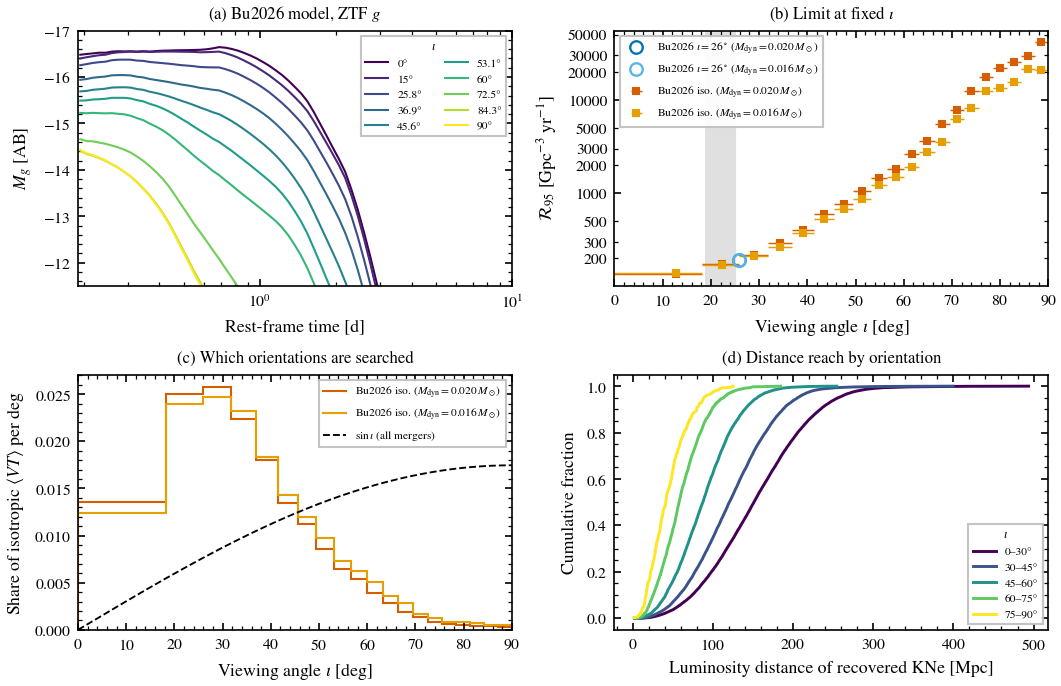

In [4]:
# Literature values to draw (remove entries to hide them). Options:
#   'mooley2022_gw170817_viewing_angle'      GW170817 viewing angle 19-25 deg (VLBI + HST)
#   'mooley2018_gw170817_viewing_angle'      GW170817 viewing angle 14-28 deg (VLBI superluminal motion)
SHOW_LITERATURE = ["mooley2022_gw170817_viewing_angle"]

selected = L.select(SHOW_LITERATURE, "other")
ISO = [m for m in ["Bu2026Vary", "GW170817_Bu2026_Isotropic"] if m in ALL]
inc = {m: A.inclination_efficiency(src, runs, m, n_bins=20) for m in ISO}
lc = snap.get("models_lightcurves")
fig, axs = plt.subplots(2, 2, figsize=(P.PAGE_WIDTH, 4.6))
(axa, axb), (axc, axd) = axs
cmap = plt.get_cmap("viridis")
if lc is not None and not lc.empty:
    s0 = lc[(lc.param_set == "suite01") & (lc.band == "g")]
    incs = sorted(s0.inclination_deg.unique())
    for k, ii in enumerate(incs):
        d = s0[s0.inclination_deg == ii].sort_values("t_days")
        axa.plot(d.t_days, d.abs_mag, color=cmap(k / max(1, len(incs) - 1)), lw=1, label=f"{ii:g}°")
    axa.set_xscale("log"); axa.set_xlim(0.19, 10); axa.set_ylim(-11.5, -17.0)
    axa.legend(loc="upper right", fontsize=5.5, ncol=2, title=r"$\iota$", title_fontsize=6)
axa.set_xlabel("Rest-frame time [d]"); axa.set_ylabel(r"$M_g$ [AB]"); axa.set_title("(a) Bu2026 model, ZTF $g$", fontsize=8)
for m, t in inc.items():
    st = P.style(m); lab = P.SHORT_LABEL[m] + P.tag(m)
    xerr = [t.iota_deg_center - t.iota_deg_lo, t.iota_deg_hi - t.iota_deg_center]
    axb.errorbar(t.iota_deg_center, t.r95, xerr=xerr, fmt=st["marker"], color=st["color"], ms=2.5, lw=0.7, label=lab)
    tt = t.sort_values("iota_deg_lo"); w = tt.vt * (tt.hi_edge - tt.lo_edge)
    edges = np.append(tt.iota_deg_lo.to_numpy(), tt.iota_deg_hi.to_numpy()[-1])
    axc.stairs((w / w.sum()).to_numpy() / (tt.iota_deg_hi - tt.iota_deg_lo).to_numpy(), edges, color=st["color"], label=lab)
for f in ["Bu2026Fixed", "GW170817_Bu2026_FixedView"]:
    if f in L_.index:
        st = P.style(f)
        axb.plot(np.degrees(0.45), L_.loc[f, "r95"], st["marker"], mfc="none", mec=st["color"], ms=6, mew=1.1,
                 label=P.SHORT_LABEL[f] + P.tag(f))
for ref, shade in zip(selected, ["0.88", "0.94"]):
    axb.axvspan(ref["low"], ref["high"], color=shade, zorder=0)
axb.set_yscale("log"); P.plain_log(axb, "y"); axb.set_xlim(0, 90); axb.set_xlabel(r"Viewing angle $\iota$ [deg]")
axb.set_ylabel(P.RATE_LABEL); axb.legend(loc="upper left", fontsize=5.5); axb.set_title(r"(b) Limit at fixed $\iota$", fontsize=8)
th = np.linspace(0, 90, 181)
axc.plot(th, np.sin(np.radians(th)) * np.pi / 180, "k--", lw=0.9, label=r"$\sin\iota$ (all mergers)")
axc.set_xlim(0, 90); axc.set_xlabel(r"Viewing angle $\iota$ [deg]"); axc.set_ylabel(r"Share of isotropic $\langle VT\rangle$ per deg")
axc.legend(loc="upper right", fontsize=5.5); axc.set_title("(c) Which orientations are searched", fontsize=8)
m0 = ISO[0]; s_ = src[src.model == m0]
edges = np.radians([0, 30, 45, 60, 75, 90])
for i in range(len(edges) - 1):
    sel = s_[(s_.inclination_rad >= edges[i]) & (s_.inclination_rad < edges[i + 1])]
    d = np.sort(A.luminosity_distance_mpc(sel.z.to_numpy()))
    axd.plot(d, np.arange(1, len(d) + 1) / len(d), color=cmap(i / (len(edges) - 2)),
             label=f"{np.degrees(edges[i]):.0f}–{np.degrees(edges[i+1]):.0f}°")
axd.set_xlabel("Luminosity distance of recovered KNe [Mpc]"); axd.set_ylabel("Cumulative fraction")
axd.legend(loc="lower right", fontsize=5.5, title=r"$\iota$", title_fontsize=6); axd.set_title("(d) Distance reach by orientation", fontsize=8)
save(fig, "fig2_inclination_anatomy"); plt.show()

**How to read this figure**

- **What is plotted:** (a) fiesta POSSIS g-band light curves of the simulated ejecta from pole-on to edge-on; (b) the 95 % limit for populations at fixed viewing angle derived from the isotropic ensembles (filled) and the independent fixed-angle ensembles (open), grey band: GW170817 VLBI angle; (c) the share of the isotropic ⟨VT⟩ contributed per degree (coloured) versus the sin ι distribution of random orientations (dashed); (d) distance distributions of recovered kilonovae in five orientation bins.
- **What it means:** brightness falls by about 2 mag in g from pole to equator, so the searched volume falls by orders of magnitude; random orientations favour the equator, but the search is dominated by near-polar events.
- **How to interpret it:** the isotropic limit is the fixed-angle limit averaged over orientations with these weights; any 'GW170817-like' limit must state its viewing-angle assumption.

## Figure 3 — Rate limits compared with previous searches and the GW BNS rate

Optical limits are drawn as vertical lines, gravitational-wave BNS rates as shaded bands.

Literature values available for the next figure (select them with the list at the top of the plotting cell):

- `andreoni2020_gw170817` — [Andreoni et al. 2020](https://arxiv.org/abs/2008.00008): ZTF (first 23 months), GW170817-like: R < 1775 Gpc^-3 yr^-1 (95%)
- `andreoni2020_possis_isotropic` — [Andreoni et al. 2020](https://arxiv.org/abs/2008.00008): ZTF (first 23 months), POSSIS, uniform viewing angle: R < 4029 Gpc^-3 yr^-1 (95% (implied))
- `andreoni2020_tophat_m16_2det` — [Andreoni et al. 2020](https://arxiv.org/abs/2008.00008): ZTF (first 23 months), top-hat M=-16, 2 detections: R < 930 Gpc^-3 yr^-1 (95%)
- `andreoni2020_linear_decline_2det` — [Andreoni et al. 2020](https://arxiv.org/abs/2008.00008): ZTF (first 23 months), linear decline M=-16.5, 0.7 mag/d, 2 det.: R < 937 Gpc^-3 yr^-1 (95%)
- `andreoni2021_ztfrest_combined` — [Andreoni et al. 2021](https://arxiv.org/abs/2104.06352): ZTF (ZTFReST + 2020 search), GW170817-like: R < 900 Gpc^-3 yr^-1 (not stated (95% per secondary source))
- `kasliwal2017_iptf` — [Kasliwal et al. 2017](https://arxiv.org/abs/1710.05436): iPTF, GW170817-like: R < 800 Gpc^-3 yr^-1 (3-sigma)
- `smartt2017_atlas` — [Smartt et al. 2017](https://arxiv.org/abs/1710.05841): ATLAS, GW170817-like: R < 30000 Gpc^-3 yr^-1 (95%)
- `doctor2017_des` — [Doctor et al. 2017](https://arxiv.org/abs/1611.08052): DES-SN, brightest model (M_i=-16.2): R < 24000 Gpc^-3 yr^-1 (90%)
- `almualla2021_ztf_simulated` — [Almualla et al. 2021](https://arxiv.org/abs/2011.10421): ZTF simulated schedules, POSSIS, cos-uniform viewing angle: R < 2749 Gpc^-3 yr^-1 (95%)
- `gwtc3_bns_rate` — [LVK GWTC-3 population (Abbott et al. 2023)](https://arxiv.org/abs/2111.03634): BNS merger rate 10-1700 Gpc^-3 yr^-1 (90%)
- `gwtc4_bns_rate` — [LVK GWTC-4.0 population (2025)](https://arxiv.org/abs/2508.18083): BNS merger rate 7.6-250 Gpc^-3 yr^-1 (90%)

/opt/anaconda3/lib/python3.11/site-packages/matplotlib/ticker.py:2920: RuntimeWarning: invalid value encountered in log10
  majorstep_no_exponent = 10 ** (np.log10(majorstep) % 1)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/ticker.py:2920: RuntimeWarning: invalid value encountered in log10
  majorstep_no_exponent = 10 ** (np.log10(majorstep) % 1)


saved paper/figures/fig3_rate_limits_master.pdf
saved paper/figures/fig3_rate_limits_master.png


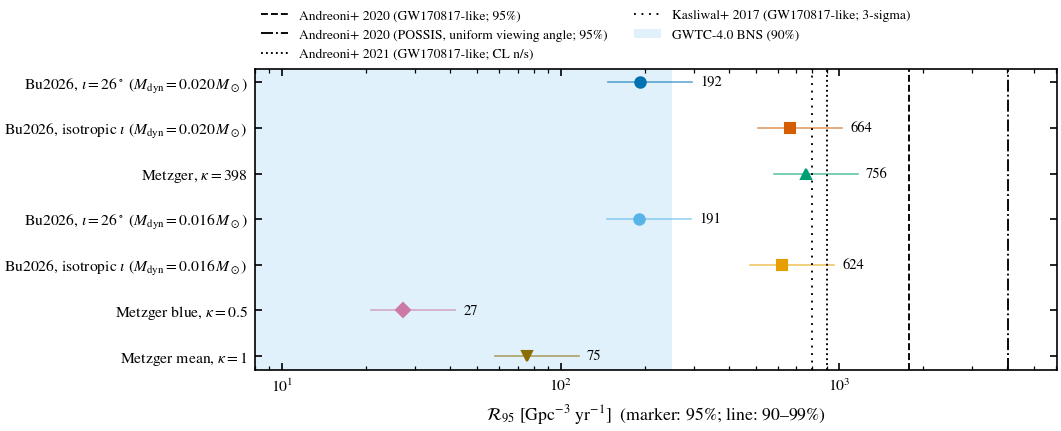

In [5]:
# Literature values to draw (remove entries to hide them). Options:
#   'andreoni2020_gw170817'                  ZTF (first 23 months), GW170817-like: R < 1775 Gpc^-3 yr^-1 (95%)
#   'andreoni2020_possis_isotropic'          ZTF (first 23 months), POSSIS, uniform viewing angle: R < 4029 Gpc^-3 yr^-1 (95% (implied))
#   'andreoni2020_tophat_m16_2det'           ZTF (first 23 months), top-hat M=-16, 2 detections: R < 930 Gpc^-3 yr^-1 (95%)
#   'andreoni2020_linear_decline_2det'       ZTF (first 23 months), linear decline M=-16.5, 0.7 mag/d, 2 det.: R < 937 Gpc^-3 yr^-1 (95%)
#   'andreoni2021_ztfrest_combined'          ZTF (ZTFReST + 2020 search), GW170817-like: R < 900 Gpc^-3 yr^-1 (not stated (95% per secondary source))
#   'kasliwal2017_iptf'                      iPTF, GW170817-like: R < 800 Gpc^-3 yr^-1 (3-sigma)
#   'smartt2017_atlas'                       ATLAS, GW170817-like: R < 30000 Gpc^-3 yr^-1 (95%)
#   'doctor2017_des'                         DES-SN, brightest model (M_i=-16.2): R < 24000 Gpc^-3 yr^-1 (90%)
#   'almualla2021_ztf_simulated'             ZTF simulated schedules, POSSIS, cos-uniform viewing angle: R < 2749 Gpc^-3 yr^-1 (95%)
#   'gwtc3_bns_rate'                         BNS merger rate 10-1700 Gpc^-3 yr^-1 (90%)
#   'gwtc4_bns_rate'                         BNS merger rate 7.6-250 Gpc^-3 yr^-1 (90%)
SHOW_LITERATURE = ["andreoni2020_gw170817", "andreoni2020_possis_isotropic", "andreoni2021_ztfrest_combined", "kasliwal2017_iptf", "gwtc4_bns_rate"]

selected = L.select(SHOW_LITERATURE)
fig, ax = plt.subplots(figsize=(P.PAGE_WIDTH, 2.9))
rows = list(L_.loc[ALL].iterrows())
y = np.arange(len(rows))[::-1]
for yi, (m, r) in zip(y, rows):
    st = P.style(m)
    ax.errorbar(r.r95, yi, xerr=r.r95_err_mc, fmt=st["marker"], color=st["color"], ms=5)
    ax.plot([r.r90, r.r99], [yi, yi], color=st["color"], lw=0.8, alpha=0.6)
    ax.annotate(f"{r.r95:.0f}", (r.r99, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=7)
styles = P.lit_line_styles(); bands = P.lit_bands()
for r in selected:
    if "limit" in r:
        cl = "CL n/s" if r["cl"].startswith("not stated") else r["cl"].replace(" (implied)", "")
        ax.axvline(r["limit"], lw=0.9, **next(styles), label=f"{r['ref'].replace(' et al.', '+')} ({r['model']}; {cl})")
    else:
        name = r["ref"].split(" population")[0].replace("LVK ", "")
        ax.axvspan(r["low"], r["high"], lw=0, zorder=0, label=f"{name} BNS (90%)", **next(bands))
ax.set_yticks(y, [P.style(m)["label"] for m, _ in rows])
ax.set_xscale("log"); ax.set_xlim(8, max([6e3, *[r.get("limit", r.get("high", 0)) * 1.5 for r in selected]])); ax.set_xlabel(P.RATE_LABEL + r"  (marker: 95%; line: 90–99%)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, frameon=False, fontsize=6.5, borderaxespad=0)
save(fig, "fig3_rate_limits_master"); plt.show()

**How to read this figure**

- **What is plotted:** the 95 % limit of every fixed-parameter model (markers, Monte Carlo error bars smaller than the symbols; thin lines span the 90–99 % limits) with published optical limits (vertical lines) and the GWTC-4.0 BNS merger rate (band).
- **What it means:** where a model's limit falls inside the band, ZTF could constrain the fraction of BNS mergers producing such a kilonova (once the real data have been searched); above the band it cannot.
- **How to interpret it:** the position of each marker relative to the band, not its absolute value, is the astrophysical result.

## Figure 4 — Recovery efficiency and distance reach of each model

saved paper/figures/fig4_recovery_distance.pdf
saved paper/figures/fig4_recovery_distance.png


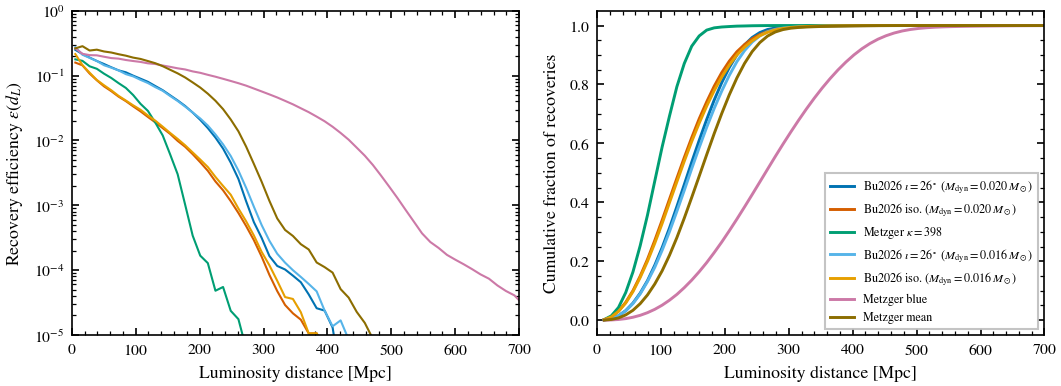

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(P.PAGE_WIDTH, 2.6))
for m in ALL:
    st = P.style(m); lab = P.SHORT_LABEL[m] + P.tag(m)
    e = A.efficiency_vs_redshift(zh, runs, m); e = e[e.n_detected > 0]
    ax1.plot(A.luminosity_distance_mpc(e.z_center.to_numpy()), e.efficiency, color=st["color"], lw=1, label=lab)
    h = zh[zh.model == m].groupby(["z_lo", "z_hi"], as_index=False)["n_detected"].sum().sort_values("z_lo")
    c = np.cumsum(h.n_detected) / h.n_detected.sum()
    ax2.plot(A.luminosity_distance_mpc(h.z_hi.to_numpy()), c, color=st["color"], label=lab)
ax1.set_yscale("log"); ax1.set_ylim(1e-5, 1); ax1.set_xlim(0, 700)
ax1.set_xlabel("Luminosity distance [Mpc]"); ax1.set_ylabel(r"Recovery efficiency $\epsilon(d_L)$")
ax2.set_xlim(0, 700); ax2.set_xlabel("Luminosity distance [Mpc]"); ax2.set_ylabel("Cumulative fraction of recoveries")
ax2.legend(loc="lower right", fontsize=5.8)
save(fig, "fig4_recovery_distance"); plt.show()

**How to read this figure**

- **What is plotted:** (left) recovery efficiency versus luminosity distance (recovered/injected per redshift bin; injections are uniform in comoving volume); (right) cumulative distance distribution of recovered injections, per model.
- **What it means:** the low-distance plateau is the survey's coverage of nearby events (sky footprint, latitude cut, cadence and fade requirement); the fall-off is set by each model's luminosity.
- **How to interpret it:** brighter models (e.g. the Metzger 'blue' preset) reach several hundred Mpc; the AT2017gfo-like POSSIS model is recovered mostly within ~150 Mpc; all curves saturate well inside the injection boundary.

## Figure 5 — Monte Carlo convergence from real realisations

saved paper/figures/fig5_convergence_and_catastrophe.pdf
saved paper/figures/fig5_convergence_and_catastrophe.png


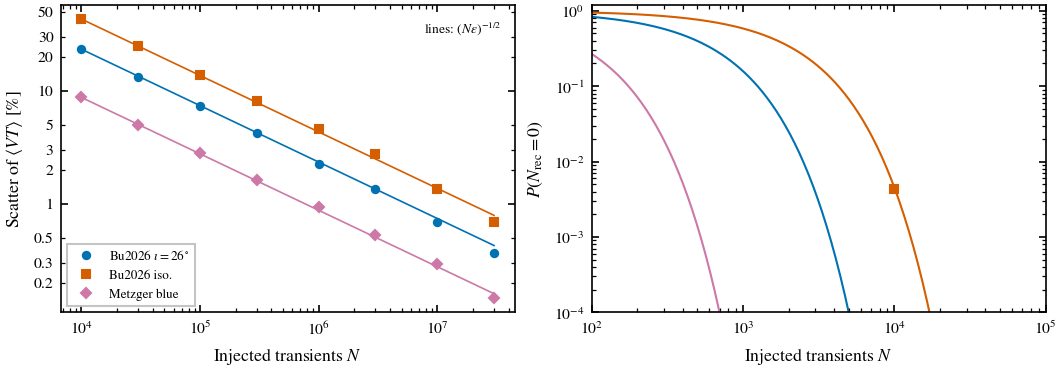

,model,n_injected,mean_k,p_zero_empirical,p_zero_poisson,rel_scatter_vt,rel_err_binomial
0,Bu2026Fixed,10000,18.43,0,9.891e-09,0.2348,0.2329
1,Bu2026Fixed,30000,55.3,0,9.678e-25,0.1326,0.1345
2,Bu2026Fixed,100000,184.6,0,8.966e-81,0.07318,0.07366
3,Bu2026Fixed,300000,552.5,0,7.207e-241,0.04203,0.04253
4,Bu2026Fixed,1000000,1843,0,0,0.02242,0.02329
5,Bu2026Fixed,3000000,5529,0,0,0.01349,0.01345
6,Bu2026Fixed,10000000,1.843e+04,0,0,0.006879,0.007366
7,Bu2026Fixed,30000000,5.53e+04,0,0,0.003619,0.004253
8,Bu2026Vary,10000,5.392,0.004333,0.00454,0.4323,0.4305
9,Bu2026Vary,30000,16.14,0,9.358e-08,0.2506,0.2486


In [7]:
SIZES = [10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000, 10_000_000, 30_000_000]
CM = [m for m in ["Bu2026Fixed", "Bu2026Vary", "GW170817_Metzger_Blue"] if m in ALL]
conv = pd.concat([A.subsampling_convergence(runs, m, SIZES, 3000) for m in CM], ignore_index=True)
fig, (ax, axz) = plt.subplots(1, 2, figsize=(P.PAGE_WIDTH, 2.5))
nn = np.logspace(2, 5, 200)
for m in CM:
    c = conv[conv.model == m]; st = P.style(m)
    ax.plot(c.n_injected, 100 * c.rel_scatter_vt, st["marker"], color=st["color"], ms=3.5, label=P.SHORT_LABEL[m])
    ax.plot(c.n_injected, 100 * c.rel_err_binomial, "-", color=st["color"], lw=0.8)
    axz.plot(nn, np.exp(-L_.loc[m, "efficiency"] * nn), color=st["color"], lw=1, label=P.SHORT_LABEL[m])
    ok = c.p_zero_empirical > 0
    axz.plot(c.n_injected[ok], c.p_zero_empirical[ok], st["marker"], color=st["color"], ms=3.5)
ax.set_xscale("log"); ax.set_yscale("log"); P.plain_log(ax, "y")
ax.set_xlabel("Injected transients $N$"); ax.set_ylabel(r"Scatter of $\langle VT\rangle$ [%]")
ax.legend(loc="lower left", fontsize=6.3)
ax.text(0.97, 0.95, r"lines: $(N\epsilon)^{-1/2}$", transform=ax.transAxes, ha="right", va="top", fontsize=6.5)
axz.set_xscale("log"); axz.set_yscale("log"); axz.set_ylim(1e-4, 1.2); axz.set_xlim(1e2, 1e5)
axz.set_xlabel("Injected transients $N$"); axz.set_ylabel(r"$P(N_{\rm rec}=0)$")
save(fig, "fig5_convergence_and_catastrophe"); plt.show()
display(conv[["model", "n_injected", "mean_k", "p_zero_empirical", "p_zero_poisson", "rel_scatter_vt", "rel_err_binomial"]])

**How to read this figure**

- **What is plotted:** (left) relative scatter of ⟨VT⟩ among simulations of $N$ injections built by sub-sampling the real realisations (markers) and the binomial expectation (lines); (right) probability that a simulation of $N$ injections recovers nothing (lines: $e^{-\epsilon N}$; markers: fraction of sub-samples).
- **What it means:** the precision of an injection–recovery limit is set by the number of recovered injections; too small a simulation can recover none at all and give no limit.
- **How to interpret it:** the production configuration ($10^6$ per realisation, $10^8$ per model) is far beyond both thresholds, so Monte Carlo noise is negligible compared with model systematics.

## Figure 6 — Criteria sensitivity (Suite 02; DEVELOPMENT ONLY until Suite 02 is re-run)

saved paper/figures/fig6_criteria_sensitivity_PRELIMINARY.pdf
saved paper/figures/fig6_criteria_sensitivity_PRELIMINARY.png


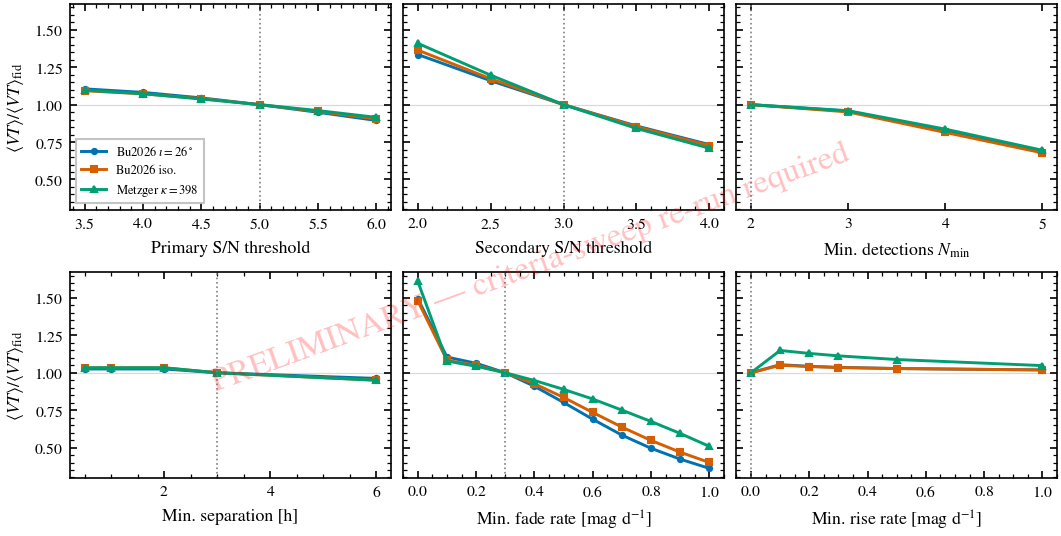

In [8]:
if "suite02_slices_1d" in snap:
    s1 = snap["suite02_slices_1d"]; fid = snap["suite02_fiducial"].set_index("model")
    FID = dict(snr_threshold=5.0, snr_threshold_secondary=3.0, min_detections=2, min_time_separation_hours=3.0,
               min_fade_rate=0.3, min_rise_rate=0.0)
    fig, axes = plt.subplots(2, 3, figsize=(P.PAGE_WIDTH, 3.6), sharey=True)
    for ax, c in zip(axes.flat, FID):
        for m in fid.index:
            d = s1[(s1.varied == c) & (s1.model == m)].sort_values(c); st = P.style(m)
            ax.plot(d[c], d.effective_vt_gpc3_yr / fid.loc[m, "effective_vt_gpc3_yr"], marker=st["marker"], ms=2.5,
                    color=st["color"], label=P.SHORT_LABEL[m])
        ax.axvline(FID[c], color="0.5", ls=":", lw=0.8); ax.axhline(1, color="0.85", lw=0.6, zorder=0)
        ax.set_xlabel(P.CRITERION_LABEL[c])
        if c == "min_detections":
            ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.xaxis.set_minor_locator(plt.NullLocator())
    for ax in axes[:, 0]:
        ax.set_ylabel(r"$\langle VT\rangle/\langle VT\rangle_{\rm fid}$")
    axes.flat[0].legend(loc="lower left", fontsize=6)
    fig.text(0.5, 0.5, "PRELIMINARY — criteria-sweep re-run required", fontsize=16, color="red", alpha=0.25,
             ha="center", va="center", rotation=20)
    save(fig, "fig6_criteria_sensitivity_PRELIMINARY"); plt.show()

**How to read this figure**

- **What is plotted:** one-at-a-time response of ⟨VT⟩ (relative to the fiducial search) to six criteria, all others fixed at the fiducial values (dotted lines), for the three Suite 02 models.
- **What it means:** the local cost in search volume of each cut; it is the basis for choosing criteria that preserve volume while rejecting contaminants.
- **How to interpret it:** PRELIMINARY until the Suite 02 ensemble is re-simulated with the current envelope; steeper curves mark the cuts that matter most.

## Table 1 — Rate limits

In [9]:
import json
def _desc(m):
    p = json.loads(runs.loc[runs.model == m, "params_json"].iloc[0])
    p = {k.lower(): v for k, v in p.items()}
    if "kappa" in p:
        return f"$M_{{\\rm ej}}={p['mej']:g}\\,M_\\odot$, $v={p['vej']:g}c$, $\\kappa={p['kappa']:g}$"
    inc = p.get("inclination_em")
    inc_s = "isotropic" if (p.get("vary_inclination") is True or inc == "varied") else f"$\\iota={np.degrees(float(inc)):.1f}^\\circ$"
    return (f"$\\log M_{{\\rm dyn}}={p['log10_mej_dyn']:g}$, $\\log M_{{\\rm wind}}={p['log10_mej_wind']:g}$, {inc_s}")
tab = lim[["model", "n_simulated", "n_detected", "vt_gpc3_yr", "vt_err_empirical", "r90", "r95", "r99"]].copy()
tab.insert(1, "suite", np.where(tab.model.str.startswith("GW170817"), "07", "01"))
tab.insert(2, "parameters", [_desc(m) for m in tab.model])
out = ROOT / "paper"
tex = tab.assign(vt=lambda d: [f"{v*1e3:.2f} $\\pm$ {e*1e3:.2f}" for v, e in zip(d.vt_gpc3_yr, d.vt_err_empirical)])
cols = ["$N_{\\rm rec}$", "$\\langle VT\\rangle$ [$10^{-3}$ Gpc$^3$ yr]", "$\\mathcal{R}_{90}$", "$\\mathcal{R}_{95}$", "$\\mathcal{R}_{99}$"]
if P.LABEL_MODE == "working":     # internal model names and the suite that produced them
    tex = tex[["model", "suite", "parameters", "n_detected", "vt", "r90", "r95", "r99"]]
    tex.columns = ["Model", "Suite", "Parameters", *cols]
    tex["Model"] = tex["Model"].str.replace("_", "\\_")
    colfmt = "lllrrrrr"
else:                              # physical description only; the parameters column tells the sets apart
    tex = tex.assign(label=[P.MODEL_STYLE[m]["label"] for m in tex.model])
    tex = tex[["label", "parameters", "n_detected", "vt", "r90", "r95", "r99"]]
    tex.columns = ["Model", "Parameters", *cols]
    colfmt = "llrrrrr"
display(tex)
if SAVE_FIGURES:                   # same switch as the figures, so previews never overwrite the paper table
    tab.to_csv(out / "table1_master_rate_limits.csv", index=False)
    (out / "table1_master_rate_limits.tex").write_text(
        tex.to_latex(index=False, escape=False, float_format="%.0f", column_format=colfmt))
    print("wrote", out / "table1_master_rate_limits.csv", "and .tex")

,Model,Parameters,$N_{\rm rec}$,$\langle VT\rangle$ [$10^{-3}$ Gpc$^3$ yr],$\mathcal{R}_{90}$,$\mathcal{R}_{95}$,$\mathcal{R}_{99}$
0,"Bu2026, $\iota=26^\circ$","$\log M_{\rm dyn}=-1.7$, $\log M_{\rm wind}=-1...",184316,15.60 $\pm$ 0.04,147.6,192,295.2
1,"Bu2026, isotropic $\iota$","$\log M_{\rm dyn}=-1.7$, $\log M_{\rm wind}=-1...",53948,4.51 $\pm$ 0.02,510,663.6,1020
2,"Metzger, $\kappa=398$","$M_{\rm ej}=0.00126\,M_\odot$, $v=0.5c$, $\kap...",47831,3.96 $\pm$ 0.02,581,755.8,1162
3,"Bu2026, $\iota=26^\circ$","$\log M_{\rm dyn}=-1.8$, $\log M_{\rm wind}=-1...",186028,15.72 $\pm$ 0.03,146.5,190.6,293
4,"Bu2026, isotropic $\iota$","$\log M_{\rm dyn}=-1.8$, $\log M_{\rm wind}=-1...",57435,4.80 $\pm$ 0.02,479.3,623.6,958.7
5,"Metzger blue, $\kappa=0.5$","$M_{\rm ej}=0.02\,M_\odot$, $v=0.25c$, $\kappa...",1316108,110.47 $\pm$ 0.09,20.84,27.12,41.69
6,"Metzger mean, $\kappa=1$","$M_{\rm ej}=0.04\,M_\odot$, $v=0.15c$, $\kappa=1$",468311,39.77 $\pm$ 0.05,57.9,75.33,115.8


wrote /Users/tbarna/Documents/GitHub/kn-rates/paper/table1_master_rate_limits.csv and .tex
